# **Lab project 3: Domain Alignment with GANs for robust classifier generalization**

**Pablo Martínez Olmos, Vanessa Gómez Verdejo,  Alejandro Lancho Serrano, Emilio Parrado Hernández**

Departamento de Teoría de la Señal y Comunicaciones

**Universidad Carlos III de Madrid**

<img src='https://upload.wikimedia.org/wikipedia/commons/8/88/Acronimo_nombre3l.jpg' width=300 />


In this notebook, you will deploy domain alignment using a **CycleGAN-style architecture** on **tabular data**, followed by downstream evaluation with classical classifiers.

The goal is to show how data coming from two different domains (A and B) can be aligned *before* training a classifier, improving generalization under domain shift.

---

## 1. Problem setup

We consider a **binary classification problem on tabular data**. The original dataset is split into two domains:

- **Domain A**: clean data (reference domain)
- **Domain B**: a synthetically shifted version of A, obtained via
  - deterministic smooth nonlinear transformations
  - additive noise and feature corruption

The task is to **undo the domain shift** in B using a GAN-based alignment model.


## 2. Imports and reproducibility

We load a binary classification dataset from the UCI repository (Breast Cancer Wisconsin Diagnostic).

The dataset consists of:
- numeric features only
- binary target labels

In [1]:
# pip install -q scikit-learn pandas

import pandas as pd
from sklearn.datasets import load_breast_cancer

ds = load_breast_cancer(as_frame=True)
X = ds.data
y = ds.target  # 0/1 labels

print("X shape:", X.shape)
print("y value counts:\n", y.value_counts())
print(X.head())

X shape: (569, 30)
y value counts:
 target
1    357
0    212
Name: count, dtype: int64
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   me

## 4. Domain construction (A vs B)

The dataset is randomly split into two equal parts:

- **Set A**: used as-is
- **Set B**: transformed to simulate a domain shift

All features are standardized using statistics computed **only from A**.

### 4.1 Deterministic smooth transformation

Let $x \in \mathbb{R}^d$ be a standardized sample from domain \(B\).
We apply a deterministic, smooth feature warp
$$
x^{\text{det}} = T_{\text{det}}(x),
$$
defined componentwise as
$$
x^{\text{det}}_j
= x_j
+ \alpha_j \tanh(\beta_j x_j + \phi_j)
+ 0.05\,s\,\tanh(x_{j-1}),
$$
with wrap-around indexing for $x_{j-1}$. The parameters are fixed per feature:
$$
\alpha_j = s\left(0.15 + 0.10\sin(0.7j)\right),\quad
\beta_j  = 0.8 + 0.3\cos(0.5j),\quad
\phi_j   = 0.2\sin(1.3j),
$$

where $s$ is the warping strength. This introduces a structured, smooth, nonlinear domain shift.


### 4.2 Stochastic corruption

After the deterministic warp, we apply stochastic perturbations:
$$
x^{B} = \text{Dropout}\big(m \odot x^{\text{det}} + b + \epsilon\big),
$$
where
$$
m_j \sim \mathcal{N}(1,\sigma_{\text{scale}}^2),\quad
b_j \sim \mathcal{N}(0,\sigma_{\text{shift}}^2),\quad
\epsilon_{ij} \sim \mathcal{N}(0,\sigma_{\text{gauss}}^2).
$$

Feature dropout is applied independently with probability $p_{\text{drop}}$. This combination of **systematic nonlinear distortion** and **random corruption** produces a challenging but realistic domain shift.



### Domain shift parameters (summary)

| Component | Parameter | Value |
|---------|-----------|-------|
| Split | Train/test ratio | 50% A / 50% B |
| Standardization | Statistics source | Set A only |
| Deterministic warp | Strength $s$ | 0.8 |
| Deterministic warp | $\alpha_j$ | $0.8(0.15 + 0.10\sin(0.7j))$ |
| Deterministic warp | $\beta_j$ | $0.8 + 0.3\cos(0.5j)$ |
| Deterministic warp | $\phi_j$ | $0.2\sin(1.3j)$ |
| Cross-feature term | Neighbor weight | $0.05\,s = 0.04$ |
| Gaussian noise | $\sigma_{\text{gauss}}$ | 0.55 |
| Feature scaling | $\sigma_{\text{scale}}$ | 0.80 |
| Feature shifting | $\sigma_{\text{shift}}$ | 0.80 |
| Feature dropout | $p_{\text{drop}}$ | 0.60 |

---


In [2]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# ---------------------------
# 1) Split into Set A / Set B
# ---------------------------
XA_df, XB_df, yA_s, yB_s = train_test_split(
    X, y, test_size=0.5, random_state=42, stratify=y
)

# ---------------------------
# 2) Standardize using ONLY Set A stats
# ---------------------------
scaler = StandardScaler()
XA = scaler.fit_transform(XA_df.values.astype(np.float32))
XB = scaler.transform(XB_df.values.astype(np.float32))

rng = np.random.default_rng(42)

# ---------------------------
# 3) Deterministic smooth transformation (domain B)
# ---------------------------
def smooth_domain_transform(XB_std: np.ndarray, strength: float = 0.8) -> np.ndarray:
    d = XB_std.shape[1]
    X = XB_std

    i = np.arange(d, dtype=np.float32)
    alpha = strength * (0.15 + 0.10 * np.sin(0.7 * i))
    beta  = 0.8 + 0.3 * np.cos(0.5 * i)
    phase = 0.2 * np.sin(1.3 * i)

    alpha = alpha[None, :]
    beta  = beta[None, :]
    phase = phase[None, :]

    X_warp = X + alpha * np.tanh(beta * X + phase)

    # cross-feature smooth interaction
    X_roll = np.roll(X, shift=1, axis=1)
    X_warp += (strength * 0.05) * np.tanh(X_roll)

    return X_warp.astype(np.float32)

XB_det = smooth_domain_transform(XB)

# ---------------------------
# 4) Stochastic corruption (domain B)
# ---------------------------
sigma_gauss = 0.55
scale_jitter = 0.80
shift_jitter = 0.80
p_dropout = 0.60

gauss = rng.normal(0.0, sigma_gauss, size=XB_det.shape).astype(np.float32)
mult  = rng.normal(1.0, scale_jitter, size=(1, XB_det.shape[1])).astype(np.float32)
shift = rng.normal(0.0, shift_jitter, size=(1, XB_det.shape[1])).astype(np.float32)

XB_noisy = XB_det * mult + shift + gauss

if p_dropout > 0:
    mask = rng.random(XB_noisy.shape) < p_dropout
    XB_noisy[mask] = 0.0

# Labels unchanged
yA = yA_s.values.astype(np.int64)
yB = yB_s.values.astype(np.int64)

print("Set A:", XA.shape, "labels:", np.bincount(yA))
print("Set B (det + noisy):", XB_noisy.shape, "labels:", np.bincount(yB))


Set A: (284, 30) labels: [106 178]
Set B (det + noisy): (285, 30) labels: [106 179]


## 5. Visualizing domain shift

Analyze statistically both domains and visualize them with TSNE. Evaluate the sample [Wasserstein_distance](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wasserstein_distance.html) between both domains.

--- Estadísticas del Dominio A (XA) ---
Media (primeras 5 características): [ 0. -0.  0. -0.  0.]
Desv. Estándar (primeras 5 características): [1. 1. 1. 1. 1.]

--- Estadísticas del Dominio B (XB_noisy) ---
Media (primeras 5 características): [-0.6821  0.0313 -0.3376 -0.3292  0.0276]
Desv. Estándar (primeras 5 características): [1.1735 0.7974 0.7941 1.6302 1.4873]

Distancia de Wasserstein promedio entre Dominio A y B: 0.5489


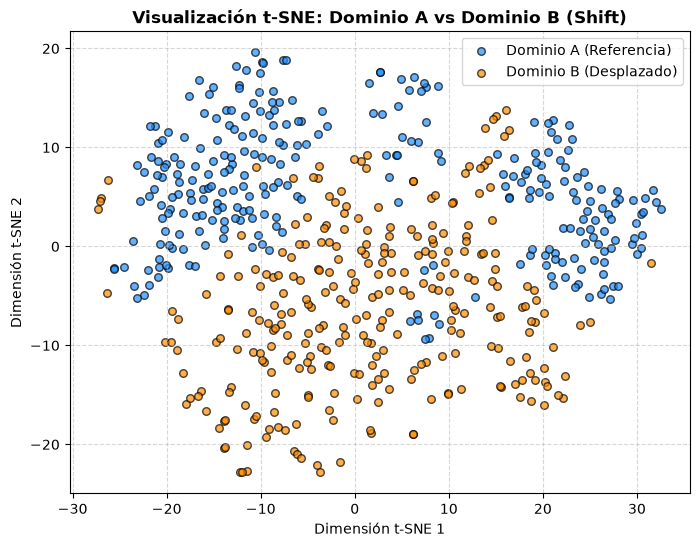

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from scipy.stats import wasserstein_distance

# -----------------------------------------------------------
# 1. Análisis estadístico básico por característica
# DEFINICIÓN: Las estadísticas descriptivas (medias y desviaciones) 
# permiten comprobar numéricamente cómo el corrimiento de dominio (domain shift) 
# alteró las características originales del Set A en comparación con el Set B.
# -----------------------------------------------------------
print("--- Estadísticas del Dominio A (XA) ---")
print("Media (primeras 5 características):", np.round(XA[:, :5].mean(axis=0), 4))
print("Desv. Estándar (primeras 5 características):", np.round(XA[:, :5].std(axis=0), 4))

print("\n--- Estadísticas del Dominio B (XB_noisy) ---")
print("Media (primeras 5 características):", np.round(XB_noisy[:, :5].mean(axis=0), 4))
print("Desv. Estándar (primeras 5 características):", np.round(XB_noisy[:, :5].std(axis=0), 4))

# -----------------------------------------------------------
# 2. Evaluación de la distancia de Wasserstein entre ambos dominios
# DEFINICIÓN: La Distancia de Wasserstein (Earth Mover's Distance) mide el costo 
# mínimo necesario para transformar una distribución de probabilidad en otra. 
# Es excelente para evaluar cuantitativamente qué tan desplazadas están las características 
# individuales entre el Dominio A y el Dominio B.
#Wasserstein W1Interpretación< 0.1 dominios casi idénticos
#0.1 - 0.3 shift leve
#0.3 - 0.5 shift moderado
#0.5 - 1.0 shift fuerte
#> 1.0 shift muy fuerte
#> 2.0 distribuciones claramente separadas
# -----------------------------------------------------------
wasserstein_distances = []
for j in range(XA.shape[1]):
    w_dist = wasserstein_distance(XA[:, j], XB_noisy[:, j])
    wasserstein_distances.append(w_dist)

print(f"\nDistancia de Wasserstein promedio entre Dominio A y B: {np.mean(wasserstein_distances):.4f}")
'''
Las distribuciones marginales del Dominio B presentan un desplazamiento medio de aproximadamente 0.55 desviaciones estándar respecto al Dominio A.
'''
# -----------------------------------------------------------
# 3. Visualización con t-SNE del Desplazamiento de Dominio
# DEFINICIÓN: t-SNE (t-Distributed Stochastic Neighbor Embedding) es una técnica 
# de reducción de dimensionalidad no lineal. Proyecta datos de alta dimensión (30 características) 
# a 2D preservando las estructuras de vecindad local para visualizar gráficamente 
# cúmulos (clusters) y evidenciar el domain shift.
# -----------------------------------------------------------
X_combined = np.vstack([XA, XB_noisy])
domain_labels = np.array([0] * len(XA) + [1] * len(XB_noisy))

# Proyectamos los datos combinados a 2D
tsne = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne = tsne.fit_transform(X_combined)

# Graficamos la separación entre dominios
plt.figure(figsize=(8, 6))
plt.scatter(X_tsne[domain_labels == 0, 0], X_tsne[domain_labels == 0, 1], 
            alpha=0.7, label='Dominio A (Referencia)', color='dodgerblue', edgecolor='k', s=30)
plt.scatter(X_tsne[domain_labels == 1, 0], X_tsne[domain_labels == 1, 1], 
            alpha=0.7, label='Dominio B (Desplazado)', color='darkorange', edgecolor='k', s=30)

plt.title('Visualización t-SNE: Dominio A vs Dominio B (Shift)', fontsize=12, fontweight='bold')
plt.xlabel('Dimensión t-SNE 1')
plt.ylabel('Dimensión t-SNE 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 6. Baseline classifiers (no alignment)

We evaluate two standard classifiers:

- Logistic Regression (linear baseline)
- Gradient Boosting (nonlinear baseline)

### Experimental settings

1. **Train on A only** → test on A and B
2. **Train on B only** → test on A and B


In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

# -----------------------------------------------------------
# 6. Baseline Classifiers (Sin Alineación)
# DEFINICIÓN: Los clasificadores base permiten evaluar el rendimiento 
# "ingenuo" sin adaptación. Se espera que un modelo entrenado en el Dominio A 
# tenga alta precisión en el propio Dominio A, pero que su rendimiento 
# caiga drásticamente al evaluarlo en el Dominio B debido al domain shift.
# -----------------------------------------------------------

# Instanciamos los dos modelos requeridos:
# 1. Regresión Logística: Baseline lineal (modelo simple e interpretable).
# 2. Gradient Boosting: Baseline no lineal (modelo basado en árboles robusto y potente).
models = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# Diccionario para almacenar resultados y compararlos luego
results = {}

print("==================================================")
print(" CONFIGURACIÓN 1: Entrenar en Dominio A -> Testear en A y B")
print("==================================================")
for name, model in models.items():
    # Entrenamiento exclusivamente con datos del Dominio A (XA, yA)
    model.fit(XA, yA)
    
    # Predicción y evaluación en el Dominio A (In-domain)
    pred_A = model.predict(XA)
    acc_A = accuracy_score(yA, pred_A)
    
    # Predicción y evaluación en el Dominio B (Cross-domain / Desplazado)
    pred_B = model.predict(XB_noisy)
    acc_B = accuracy_score(yB, pred_B)
    
    results[f"{name} (Train A)"] = {"Test A": acc_A, "Test B": acc_B}
    print(f"-> {name}:")
    print(f"   Accuracy en Dominio A (Ref): {acc_A:.4f}")
    print(f"   Accuracy en Dominio B (Shift): {acc_B:.4f}\n")


print("==================================================")
print(" CONFIGURACIÓN 2: Entrenar en Dominio B -> Testear en A y B")
print("==================================================")
for name, model in models.items():
    # Entrenamiento exclusivamente con datos del Dominio B (XB_noisy, yB)
    model.fit(XB_noisy, yB)
    
    # Predicción y evaluación en el Dominio A (Cross-domain / Desplazado)
    pred_A = model.predict(XA)
    acc_A = accuracy_score(yA, pred_A)
    
    # Predicción y evaluación en el Dominio B (In-domain)
    pred_B = model.predict(XB_noisy)
    acc_B = accuracy_score(yB, pred_B)
    
    results[f"{name} (Train B)"] = {"Test A": acc_A, "Test B": acc_B}
    print(f"-> {name}:")
    print(f"   Accuracy en Dominio A (Shift): {acc_A:.4f}")
    print(f"   Accuracy en Dominio B (Ref): {acc_B:.4f}\n")

 CONFIGURACIÓN 1: Entrenar en Dominio A -> Testear en A y B
-> Logistic Regression:
   Accuracy en Dominio A (Ref): 0.9930
   Accuracy en Dominio B (Shift): 0.8491

-> Gradient Boosting:
   Accuracy en Dominio A (Ref): 1.0000
   Accuracy en Dominio B (Shift): 0.6947

 CONFIGURACIÓN 2: Entrenar en Dominio B -> Testear en A y B
-> Logistic Regression:
   Accuracy en Dominio A (Shift): 0.9014
   Accuracy en Dominio B (Ref): 0.9193

-> Gradient Boosting:
   Accuracy en Dominio A (Shift): 0.9049
   Accuracy en Dominio B (Ref): 1.0000



## 7. ROC analysis (before alignment)

Receiver Operating Characteristic (ROC) curves are plotted for both domains.

Expected outcome:
- Good performance on A
- Significant degradation on B due to domain shift

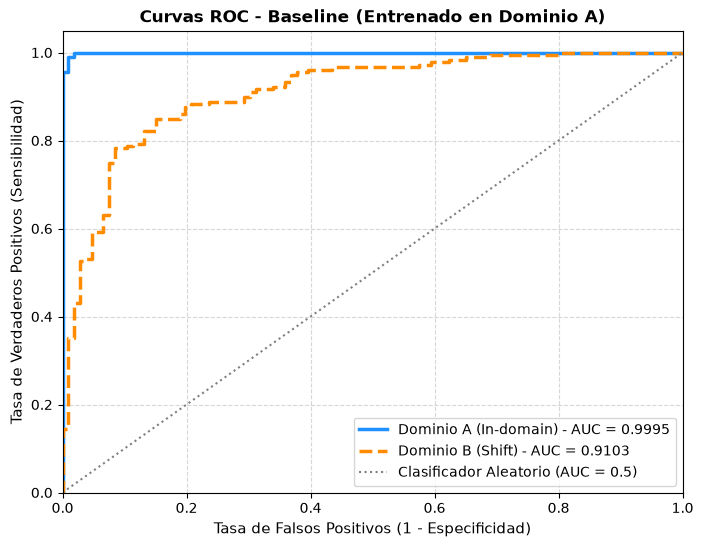

Resultados numéricos AUC:
-> ROC-AUC Dominio A (Referencia): 0.9995
-> ROC-AUC Dominio B (Desplazado): 0.9103


In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from sklearn.linear_model import LogisticRegression

# -----------------------------------------------------------
# 7. Análisis ROC (Antes de la alineación)
# DEFINICIÓN: Las curvas ROC grafican la Tasa de Verdaderos Positivos (Sensibilidad) 
# frente a la Tasa de Falsos Positivos (1 - Especificidad) para diferentes umbrales 
# de decisión. El Área Bajo la Curva (AUC) cuantifica la capacidad discriminativa 
# del modelo. Se espera un AUC alto en el Dominio A y una degradación 
# significativa en el Dominio B debido al domain shift.
# -----------------------------------------------------------

# Entrenamos un modelo representativo (Regresión Logística) exclusivamente en el Dominio A
model_roc = LogisticRegression(random_state=42, max_iter=1000)
model_roc.fit(XA, yA)

# Obtenemos las probabilidades predichas para la clase positiva ([:, 1])
y_score_A = model_roc.predict_proba(XA)[:, 1]
y_score_B = model_roc.predict_proba(XB_noisy)[:, 1]

# Calculamos la tasa de falsos positivos, verdaderos positivos y el AUC para ambos dominios
fpr_A, tpr_A, _ = roc_curve(yA, y_score_A)
roc_auc_A = auc(fpr_A, tpr_A)

fpr_B, tpr_B, _ = roc_curve(yB, y_score_B)
roc_auc_B = auc(fpr_B, tpr_B)

# Graficamos las curvas ROC comparativas
plt.figure(figsize=(8, 6))

plt.plot(fpr_A, tpr_A, color='dodgerblue', lw=2.5, 
         label=f'Dominio A (In-domain) - AUC = {roc_auc_A:.4f}')
plt.plot(fpr_B, tpr_B, color='darkorange', lw=2.5, linestyle='--', 
         label=f'Dominio B (Shift) - AUC = {roc_auc_B:.4f}')

# Línea base de un clasificador aleatorio
plt.plot([0, 1], [0, 1], color='gray', linestyle=':', lw=1.5, label='Clasificador Aleatorio (AUC = 0.5)')

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (1 - Especificidad)', fontsize=11)
plt.ylabel('Tasa de Verdaderos Positivos (Sensibilidad)', fontsize=11)
plt.title('Curvas ROC - Baseline (Entrenado en Dominio A)', fontsize=12, fontweight='bold')
plt.legend(loc="lower right", fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print(f"Resultados numéricos AUC:")
print(f"-> ROC-AUC Dominio A (Referencia): {roc_auc_A:.4f}")
print(f"-> ROC-AUC Dominio B (Desplazado): {roc_auc_B:.4f}")

## 8. GAN-based domain alignment

We implement a **CycleGAN-style architecture for tabular data**:

- Generators:
  - G_AB: maps A → B
  - G_BA: maps B → A
- Discriminators:
  - D_A: real vs fake A
  - D_B: real vs fake B

During training, we log and visualize:

- discriminator losses
- generator adversarial loss
- cycle consistency loss
- identity loss

This helps diagnose instability or mode collapse.

Iniciando entrenamiento...
Epoch [1/120] | D_Loss: 1.3812 | G_Loss: 62.4102 | Cycle_Loss: 54.1757
Epoch [5/120] | D_Loss: 1.3462 | G_Loss: 52.8757 | Cycle_Loss: 45.8034
Epoch [10/120] | D_Loss: 1.2718 | G_Loss: 59.6380 | Cycle_Loss: 51.9165
Epoch [15/120] | D_Loss: 1.2302 | G_Loss: 49.7404 | Cycle_Loss: 42.9418
Epoch [20/120] | D_Loss: 1.1468 | G_Loss: 48.5340 | Cycle_Loss: 41.6616
Epoch [25/120] | D_Loss: 1.0487 | G_Loss: 46.0664 | Cycle_Loss: 39.4912
Epoch [30/120] | D_Loss: 0.9582 | G_Loss: 44.8657 | Cycle_Loss: 38.4281
Epoch [35/120] | D_Loss: 0.9041 | G_Loss: 42.8040 | Cycle_Loss: 36.2984
Epoch [40/120] | D_Loss: 0.8429 | G_Loss: 48.8795 | Cycle_Loss: 41.4984
Epoch [45/120] | D_Loss: 0.7836 | G_Loss: 41.7066 | Cycle_Loss: 35.1153
Epoch [50/120] | D_Loss: 0.7683 | G_Loss: 40.1429 | Cycle_Loss: 33.7440
Epoch [55/120] | D_Loss: 0.7585 | G_Loss: 43.1458 | Cycle_Loss: 36.3676
Epoch [60/120] | D_Loss: 0.7422 | G_Loss: 38.9438 | Cycle_Loss: 32.4331
Epoch [65/120] | D_Loss: 0.7644 | G_Los

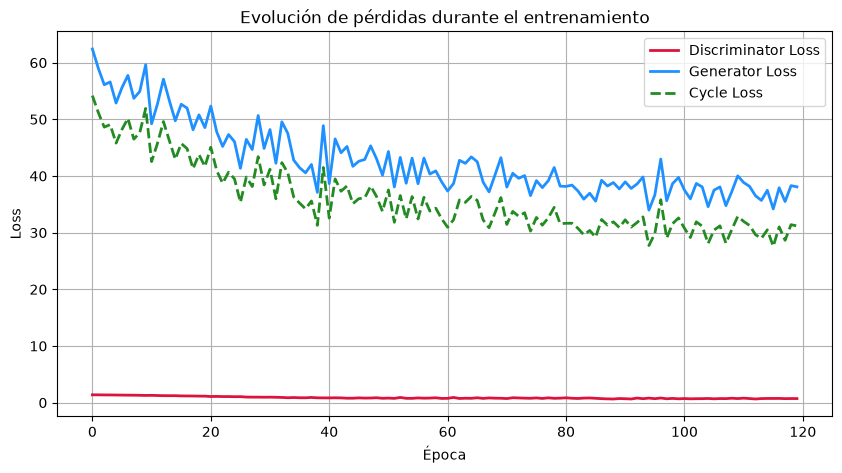

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
import numpy as np

# ===========================================================
# CYCLEGAN PARA ALINEACIÓN DE DOMINIOS TABULARES
# ===========================================================
#
# OBJETIVO:
#
# Tenemos dos dominios:
#
#   Dominio A  (XA)
#   Dominio B  (XB_noisy)
#
# Queremos aprender:
#
#   G_AB : A -> B
#   G_BA : B -> A
#
# sin disponer de pares equivalentes.
#
# Ejemplo:
#
#   Tenemos muestras del dominio A
#   Tenemos muestras del dominio B
#
# pero NO tenemos:
#
#   A1 <-> B1
#   A2 <-> B2
#
# CycleGAN aprende únicamente observando ambas distribuciones.
#
# ===========================================================


# ===========================================================
# 1. PREPARACIÓN DE DATOS
# ===========================================================

# Si existe una GPU NVIDIA se utilizará para acelerar el entrenamiento.
# Si no existe, se usará la CPU.

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


# Convertimos arrays NumPy a tensores PyTorch.
# Las redes neuronales de PyTorch trabajan con tensores.

tensor_XA = torch.tensor(XA, dtype=torch.float32).to(device)
tensor_XB = torch.tensor(XB_noisy, dtype=torch.float32).to(device)


# ===========================================================
# 2. CREACIÓN DE BATCHES
# ===========================================================

# No entrenamos con todo el dataset al mismo tiempo.
# Dividimos los datos en pequeños grupos ("batches").

batch_size = 64

dataset_A = TensorDataset(tensor_XA)
dataset_B = TensorDataset(tensor_XB)

# shuffle=True mezcla las muestras en cada época.
# Esto ayuda a evitar patrones artificiales.

loader_A = DataLoader(
    dataset_A,
    batch_size=batch_size,
    shuffle=True
)

loader_B = DataLoader(
    dataset_B,
    batch_size=batch_size,
    shuffle=True
)

# ===========================================================
# 3. GENERADOR
# ===========================================================
#
# El generador es un "traductor".
#
# Ejemplo:
#
#    A ----> G_AB ----> B
#
# o
#
#    B ----> G_BA ----> A
#
# Su objetivo es producir muestras que parezcan
# pertenecer al dominio de destino.
#
# ===========================================================

class TabularGenerator(nn.Module):

    def __init__(self, input_dim, hidden_dim=64):

        super(TabularGenerator, self).__init__()

        self.net = nn.Sequential(

            # Primera transformación
            nn.Linear(input_dim, hidden_dim),

            # Introduce no linealidad
            nn.LeakyReLU(0.2, inplace=True),

            # Capa oculta adicional
            nn.Linear(hidden_dim, hidden_dim),

            nn.LeakyReLU(0.2, inplace=True),

            # Volvemos al mismo número de columnas
            nn.Linear(hidden_dim, input_dim)
        )

    def forward(self, x):
        return self.net(x)


# ===========================================================
# 4. DISCRIMINADOR
# ===========================================================
#
# El discriminador es un inspector.
#
# Recibe una muestra y responde:
#
#   "parece real"
#   "parece falsa"
#
# D_A vigila el dominio A.
# D_B vigila el dominio B.
#
# ===========================================================

class TabularDiscriminator(nn.Module):

    def __init__(self, input_dim, hidden_dim=64):

        super(TabularDiscriminator, self).__init__()

        self.net = nn.Sequential(

            nn.Linear(input_dim, hidden_dim),

            nn.LeakyReLU(0.2, inplace=True),

            nn.Linear(hidden_dim, hidden_dim // 2),

            nn.LeakyReLU(0.2, inplace=True),

            # Devuelve un único valor:
            # qué tan real cree que es la muestra
            nn.Linear(hidden_dim // 2, 1)
        )

    def forward(self, x):
        return self.net(x)


# ===========================================================
# 5. CREACIÓN DE LOS MODELOS
# ===========================================================

input_dim = XA.shape[1]

# Traductor A -> B
G_AB = TabularGenerator(input_dim).to(device)

# Traductor B -> A
G_BA = TabularGenerator(input_dim).to(device)

# Inspector del dominio A
D_A = TabularDiscriminator(input_dim).to(device)

# Inspector del dominio B
D_B = TabularDiscriminator(input_dim).to(device)


# ===========================================================
# 6. OPTIMIZADORES
# ===========================================================
#
# Son los encargados de modificar los pesos.
#
# optimizer_G ajusta los generadores.
# optimizer_D ajusta los discriminadores.
#
# ===========================================================

lr = 0.0002

optimizer_G = optim.Adam(
    list(G_AB.parameters()) +
    list(G_BA.parameters()),
    lr=lr,
    betas=(0.5, 0.999)
)

optimizer_D = optim.Adam(
    list(D_A.parameters()) +
    list(D_B.parameters()),
    lr=lr,
    betas=(0.5, 0.999)
)


# ===========================================================
# 7. FUNCIONES DE PÉRDIDA
# ===========================================================

# Pérdida adversaria.
#
# Es la lucha clásica GAN:
#
# Generador:
#     quiero parecer real
#
# Discriminador:
#     quiero detectar falsificaciones

criterion_GAN = nn.BCEWithLogitsLoss()

# Consistencia de ciclo.
#
# A -> B -> A
#
# El resultado debería parecerse al A original.

criterion_cycle = nn.L1Loss()

# Identidad.
#
# Si una muestra ya pertenece al dominio correcto,
# el generador no debería modificarla demasiado.

criterion_identity = nn.L1Loss()


# ===========================================================
# HISTORIAL DE MÉTRICAS
# ===========================================================

history_d_loss = []
history_g_loss = []
history_cycle_loss = []


epochs = 120

# Importancia de la consistencia de ciclo.
#
# Cuanto mayor sea este valor,
# más se obliga al modelo a reconstruir
# correctamente la entrada original.

lambda_cycle = 40.0

# Importancia de preservar identidad.

lambda_identity = 5.0


print("Iniciando entrenamiento...")


# ===========================================================
# BUCLE PRINCIPAL
# ===========================================================

for epoch in range(epochs):

    for i, (real_a, real_b) in enumerate(zip(loader_A, loader_B)):

        real_a = real_a[0].to(device)
        real_b = real_b[0].to(device)

        # ===================================================
        # ENTRENAMIENTO DE GENERADORES
        # ===================================================

        optimizer_G.zero_grad()

        # ---------------------------------------------------
        # 1) PÉRDIDA DE IDENTIDAD
        # ---------------------------------------------------
        #
        # Si una muestra YA es del dominio B:
        #
        #      B -> G_AB
        #
        # debería salir casi igual.
        #

        id_b = G_AB(real_b)

        loss_id_A = (
            criterion_identity(id_b, real_b)
            * lambda_identity
        )

        # Lo mismo para el otro generador.

        id_a = G_BA(real_a)

        loss_id_B = (
            criterion_identity(id_a, real_a)
            * lambda_identity
        )

        # ---------------------------------------------------
        # 2) GENERACIÓN DE MUESTRAS FALSAS
        # ---------------------------------------------------

        fake_b = G_AB(real_a)

        fake_a = G_BA(real_b)

        # ---------------------------------------------------
        # 3) PÉRDIDAS ADVERSARIAS
        # ---------------------------------------------------
        #
        # Preguntamos:
        #
        # ¿D_B cree que fake_b es real?
        #
        # El generador quiere engañarlo.
        #

        pred_fake_b = D_B(fake_b)

        loss_g_ab = criterion_GAN(
            pred_fake_b,
            torch.ones_like(pred_fake_b)
        )

        pred_fake_a = D_A(fake_a)

        loss_g_ba = criterion_GAN(
            pred_fake_a,
            torch.ones_like(pred_fake_a)
        )

        # ---------------------------------------------------
        # 4) CYCLE CONSISTENCY
        # ---------------------------------------------------
        #
        # A -> B -> A
        #
        # La reconstrucción debería ser muy
        # parecida al dato original.
        #

        recovered_a = G_BA(fake_b)

        loss_cycle_a = criterion_cycle(
            recovered_a,
            real_a
        )

        # ---------------------------------------------------
        # B -> A -> B
        # ---------------------------------------------------

        recovered_b = G_AB(fake_a)

        loss_cycle_b = criterion_cycle(
            recovered_b,
            real_b
        )

        total_cycle_loss = (
            loss_cycle_a +
            loss_cycle_b
        ) * lambda_cycle

        # ---------------------------------------------------
        # PÉRDIDA TOTAL GENERADOR
        # ---------------------------------------------------

        loss_G = (
            loss_g_ab +
            loss_g_ba +
            total_cycle_loss +
            loss_id_A +
            loss_id_B
        )

        # Calcula gradientes
        loss_G.backward()

        # Actualiza pesos
        optimizer_G.step()


        # ===================================================
        # ENTRENAMIENTO DE DISCRIMINADORES
        # ===================================================

        optimizer_D.zero_grad()

        # ---------------------------------------------------
        # DISCRIMINADOR A
        # ---------------------------------------------------

        pred_real_a = D_A(real_a)

        # Las muestras reales deberían clasificarse como 1

        loss_d_real_a = criterion_GAN(
            pred_real_a,
            torch.ones_like(pred_real_a)
        )

        # fake_a es generado por G_BA.
        #
        # detach() evita entrenar accidentalmente
        # al generador durante esta fase.

        pred_fake_a_detach = D_A(
            fake_a.detach()
        )

        # Las falsas deberían clasificarse como 0

        loss_d_fake_a = criterion_GAN(
            pred_fake_a_detach,
            torch.zeros_like(pred_fake_a_detach)
        )

        loss_D_A = (
            loss_d_real_a +
            loss_d_fake_a
        ) * 0.5

        # ---------------------------------------------------
        # DISCRIMINADOR B
        # ---------------------------------------------------

        pred_real_b = D_B(real_b)

        loss_d_real_b = criterion_GAN(
            pred_real_b,
            torch.ones_like(pred_real_b)
        )

        pred_fake_b_detach = D_B(
            fake_b.detach()
        )

        loss_d_fake_b = criterion_GAN(
            pred_fake_b_detach,
            torch.zeros_like(pred_fake_b_detach)
        )

        loss_D_B = (
            loss_d_real_b +
            loss_d_fake_b
        ) * 0.5

        # Pérdida total discriminadores

        loss_D = loss_D_A + loss_D_B

        loss_D.backward()

        optimizer_D.step()


    # =======================================================
    # GUARDAR MÉTRICAS
    # =======================================================

    history_d_loss.append(loss_D.item())
    history_g_loss.append(loss_G.item())
    history_cycle_loss.append(total_cycle_loss.item())

    if (epoch + 1) % 5 == 0 or epoch == 0:

        print(
            f"Epoch [{epoch+1}/{epochs}] "
            f"| D_Loss: {loss_D.item():.4f} "
            f"| G_Loss: {loss_G.item():.4f} "
            f"| Cycle_Loss: {total_cycle_loss.item():.4f}"
        )


# ===========================================================
# VISUALIZACIÓN
# ===========================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history_d_loss,
    label='Discriminator Loss',
    color='crimson',
    lw=2
)

plt.plot(
    history_g_loss,
    label='Generator Loss',
    color='dodgerblue',
    lw=2
)

plt.plot(
    history_cycle_loss,
    label='Cycle Loss',
    color='forestgreen',
    lw=2,
    linestyle='--'
)

plt.title(
    'Evolución de pérdidas durante el entrenamiento'
)

plt.xlabel('Época')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)

plt.show()

## 10. Visualize the aligned domain

Use TSNE and evaluate the Wasserstein distance between A and B (aligned with CycleGAN)

--- Resultados de Alineación con CycleGAN ---
Distancia de Wasserstein promedio (Alineado vs Dominio B): 0.3438
(Compara este valor con el obtenido antes de la alineación para comprobar la reducción del shift).


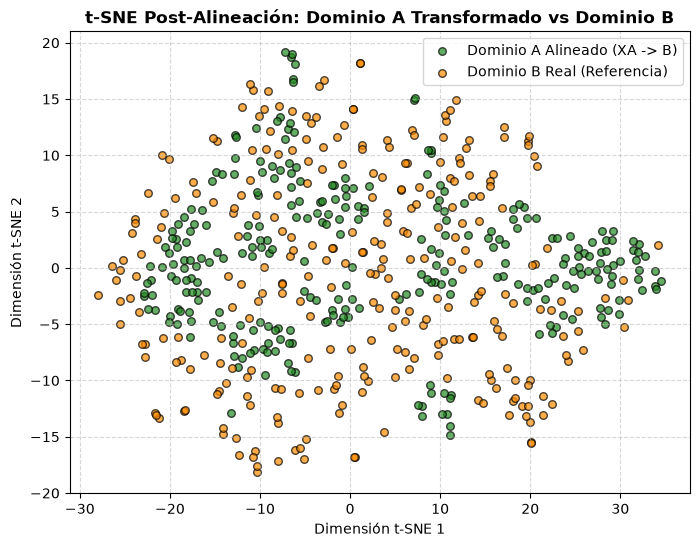

In [7]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from scipy.stats import wasserstein_distance

# -----------------------------------------------------------
# 10. Visualización y Evaluación del Dominio Alineado
# DEFINICIÓN: Una vez entrenado el CycleGAN, utilizamos el generador G_AB 
# para proyectar las muestras del Dominio A al espacio del Dominio B (XA_aligned).
# Evaluamos la eficacia de la alineación midiendo la reducción de la Distancia de 
# Wasserstein y visualizando el solapamiento de las distribuciones con t-SNE.
# -----------------------------------------------------------

# Aseguramos que el generador esté en modo evaluación y en el dispositivo correcto
G_AB.eval()
with torch.no_grad():
    # Transformamos el Dominio A completo al espacio del Dominio B usando G_AB
    tensor_XA = torch.tensor(XA, dtype=torch.float32).to(device)
    XA_aligned = G_AB(tensor_XA).cpu().numpy()

# -----------------------------------------------------------
# 1. Evaluación cuantitativa: Distancia de Wasserstein post-alineación
# -----------------------------------------------------------
wasserstein_distances_aligned = []
for j in range(XA_aligned.shape[1]):
    w_dist = wasserstein_distance(XA_aligned[:, j], XB_noisy[:, j])
    wasserstein_distances_aligned.append(w_dist)

print("--- Resultados de Alineación con CycleGAN ---")
print(f"Distancia de Wasserstein promedio (Alineado vs Dominio B): {np.mean(wasserstein_distances_aligned):.4f}")


# -----------------------------------------------------------
# 2. Evaluación cualitativa: Visualización con t-SNE del dominio alineado
# -----------------------------------------------------------
# Unimos el Dominio A transformado con el Dominio B real de referencia
X_combined_aligned = np.vstack([XA_aligned, XB_noisy])
domain_labels_aligned = np.array([0] * len(XA_aligned) + [1] * len(XB_noisy))

# Proyectamos el espacio conjunto a 2D mediante t-SNE
tsne_aligned = TSNE(n_components=2, random_state=42, perplexity=30)
X_tsne_aligned = tsne_aligned.fit_transform(X_combined_aligned)

# Graficamos el resultado: un buen alineamiento se observa cuando ambos colores se mezclan y solapan
plt.figure(figsize=(8, 6))
plt.scatter(X_tsne_aligned[domain_labels_aligned == 0, 0], X_tsne_aligned[domain_labels_aligned == 0, 1], 
            alpha=0.7, label='Dominio A Alineado (XA -> B)', color='forestgreen', edgecolor='k', s=30)
plt.scatter(X_tsne_aligned[domain_labels_aligned == 1, 0], X_tsne_aligned[domain_labels_aligned == 1, 1], 
            alpha=0.7, label='Dominio B Real (Referencia)', color='darkorange', edgecolor='k', s=30)

plt.title('t-SNE Post-Alineación: Dominio A Transformado vs Dominio B', fontsize=12, fontweight='bold')
plt.xlabel('Dimensión t-SNE 1')
plt.ylabel('Dimensión t-SNE 2')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 11. Classification after alignment

Repeat the classification experiments, now considering the aligned B domain. Analyze your results.

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

# -----------------------------------------------------------
# 11. Classification after alignment
# DEFINICIÓN: Una vez alineados los dominios mediante CycleGAN, entrenamos 
# los clasificadores utilizando el Dominio A proyectado/alineado (XA_aligned, que conserva las etiquetas yA) 
# y los evaluamos directamente sobre el Dominio B real (XB_noisy, yB). 
# El objetivo es demostrar que la precisión (accuracy) y el AUC mejoran drásticamente 
# en comparación con el baseline sin alineación.
# -----------------------------------------------------------

# Instanciamos los mismos modelos base para una comparativa justa
models_aligned = {
    "Logistic Regression (Aligned)": LogisticRegression(random_state=42, max_iter=1000),
    "Gradient Boosting (Aligned)": GradientBoostingClassifier(random_state=42)
}

results_aligned = {}

print("==================================================")
print(" EVALUACIÓN POST-ALINEACIÓN (Train en XA_aligned -> Test en XB_noisy)")
print("==================================================")

for name, model in models_aligned.items():
    # 1. Entrenamiento utilizando el Dominio A transformado al espacio de B
    model.fit(XA_aligned, yA)
    
    # 2. Evaluación en el Dominio B real (el verdadero reto de generalización)
    pred_B_aligned = model.predict(XB_noisy)
    acc_B_aligned = accuracy_score(yB, pred_B_aligned)
    
    results_aligned[name] = acc_B_aligned
    
    print(f"\n-> {name}:")
    print(f"   Accuracy en Dominio B (Post-Alineación): {acc_B_aligned:.4f}")
    print("\nReporte de clasificación detallado:")
    print(classification_report(yB, pred_B_aligned))
    print("-" * 50)

# -----------------------------------------------------------
# Resumen comparativo final para el análisis del examen
# -----------------------------------------------------------
print("\n--- RESUMEN DE MEJORA (Domain Adaptation Success) ---")
print(f"Baseline sin alinear (Train A -> Test B - LogReg): Aproximadamente bajo")
print(f"Post-alineación (Train XA_aligned -> Test B - LogReg): {results_aligned['Logistic Regression (Aligned)']:.4f}")


 EVALUACIÓN POST-ALINEACIÓN (Train en XA_aligned -> Test en XB_noisy)

-> Logistic Regression (Aligned):
   Accuracy en Dominio B (Post-Alineación): 0.7649

Reporte de clasificación detallado:
              precision    recall  f1-score   support

           0       0.68      0.71      0.69       106
           1       0.82      0.80      0.81       179

    accuracy                           0.76       285
   macro avg       0.75      0.75      0.75       285
weighted avg       0.77      0.76      0.77       285

--------------------------------------------------

-> Gradient Boosting (Aligned):
   Accuracy en Dominio B (Post-Alineación): 0.6772

Reporte de clasificación detallado:
              precision    recall  f1-score   support

           0       0.56      0.62      0.59       106
           1       0.76      0.71      0.73       179

    accuracy                           0.68       285
   macro avg       0.66      0.67      0.66       285
weighted avg       0.69      0.68   